In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler

In [2]:
SM_data_all = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_7-10-2024.txt')
#import missing data files
cmi_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_CMI.csv')
mon_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_MON.csv')
siu_data = pd.read_csv('/data/keeling/a/cstraus2/Phd_research/T_Ford_SIU.csv')
#set station ID to be one ID, currently has two one with and one without spaces
cmi_data['Station']= 'cmi'
mon_data['Station'] = 'mon'
siu_data['Station'] = 'siu'

#change column names to match, have 'Precip' and 'preciptation'
cmi_data['Precipitation (in)'] = cmi_data['Precip (in)']
mon_data['Precipitation (in)'] = mon_data['Precip (in)']
siu_data['Precipitation (in)'] = siu_data['Precip (in)']

cmi_data['Date & Time (CST)'] = pd.to_datetime(cmi_data['Date & Time (CST)'])
mon_data['Date & Time (CST)'] = pd.to_datetime(mon_data['Date & Time (CST)'])
siu_data['Date & Time (CST)'] = pd.to_datetime(siu_data['Date & Time (CST)'])
SM_data_all['Date & Time (CST)'] = pd.to_datetime(SM_data_all['Date & Time (CST)'].str[:19])
#concatenate all data
SM_data_all = pd.concat([SM_data_all, cmi_data, mon_data, siu_data], axis = 0)
SM_data_all = SM_data_all.reset_index(drop = True)
SM_data_all = SM_data_all.drop('Precip (in)', axis = 1)
#drop 2008 data because they switched from bucket weight units to inches per hour, data complete mess.
SM_data_all['Year'] = SM_data_all['Date & Time (CST)'].dt.year
SM_data_all = SM_data_all[SM_data_all['Year'] != 2008]
SM_data_all = SM_data_all.drop('Year', axis = 1)

What is wfv?
water fraction volume cm3/cm3 volumetric fraction of soil column that is water (relative to total 
absolut volume)
metadata:
https://www.isws.illinois.edu/warm/climnet/stnmetadata.asp


# Data is not in order and soil moisture values =<0 and >0.7 need to be removed, replace with NaN

we are assuming no data means there is no rain since we cannot measure ammount and precipitation and
we are only concerned with the peak values and difference and can assume cutting some events short 
or not including them has low impact on the peak values and changes

## remove rain that is over 3 in/hr rate, these are unlikely to be true for Illinois and only occur a handful of times in the entire datasets
## set unprobable threshold to remove for isolate rainrates, ie if precip is over 2 in/hr but there is no precip for timestep before and after it is unlikely to be a real measurement 


round to hundredths any smaller is beyond sensor capabilites

In [10]:
SM_data_all

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv)
0,bbc,2010-07-16 12:00:00,0.0,0.237,0.270,0.154,0.167,0.164,0.077
1,bbc,2010-07-16 13:00:00,0.0,0.236,0.266,0.152,0.168,0.164,0.077
2,bbc,2010-07-16 14:00:00,0.0,0.235,0.266,0.152,0.167,0.162,0.079
3,bbc,2010-07-16 15:00:00,0.0,0.234,0.265,0.152,0.166,0.163,0.078
4,bbc,2010-07-16 16:00:00,0.0,0.233,0.265,0.152,0.168,0.163,0.077
...,...,...,...,...,...,...,...,...,...
2714121,siu,2023-12-31 20:00:00,0.0,0.317,0.362,0.322,0.298,0.298,0.461
2714122,siu,2023-12-31 21:00:00,0.0,0.318,0.362,0.323,0.299,0.297,0.461
2714123,siu,2023-12-31 22:00:00,0.0,0.317,0.361,0.323,0.300,0.295,0.461
2714124,siu,2023-12-31 23:00:00,0.0,0.317,0.361,0.323,0.298,0.296,0.461


In [3]:
#clean data, remove impossible values
def clean_data(data,precip_cutoff, sm_cutoff, unlikely_threshold):
    data = data.copy()
    Data_column_names = data.columns[data.columns.str.contains('Soil Moisture')].tolist()
    #['Soil Moisture 5cm (wfv)', 'Soil Moisture 10cm (wfv)', 
                     #'Soil Moisture 20cm (wfv)','Soil Moisture 50cm (wfv)', 
                     #'Soil Moisture 100cm (wfv)', 'Soil Moisture 150cm (wfv)']
    for i in range(len(Data_column_names)):
        data.loc[data[Data_column_names[i]] <= 0, Data_column_names[i]] = np.NaN 
        data.loc[data[Data_column_names[i]] >sm_cutoff, Data_column_names[i]] = np.NaN
        #data[Data_column_names[i]] = data[Data_column_names[i]].round(decimals = 2)

    #data['Precipitation (in)'] = data['Precipitation (in)'].round(decimals = 2)

    data.loc[data['Precipitation (in)'] > precip_cutoff, 'Precipitation (in)'] =np.NaN
    data['Precipitation_diff'] = np.NaN
    data['Precipitation_downshift'] = np.NaN
    data['Precipitation_upshift'] = np.NaN

    
    
    #station's data are not linear, but scrabmled, put in order
    Stations = list(data.Station.unique())
    first_station = Stations[0]
    for s in Stations:
        station_data = data.loc[data['Station'] == s]

        station_data = station_data.sort_values(by = 'Date & Time (CST)')
        station_data = station_data.reset_index(drop = True)

        station_data['Precipitation_diff'] = station_data['Precipitation (in)'].diff()
        station_data['Precipitation_downshift'] = station_data['Precipitation (in)'].shift(1)
        station_data[ 'Precipitation_upshift'] = station_data['Precipitation (in)'].shift(-1)

        if s == first_station:
            new_df = station_data
        else:
            new_df = pd.concat([new_df, station_data], axis = 0)

    new_df = new_df.reset_index(drop = True)
    #switch unlikely events with Nan
    new_df.loc[(new_df['Precipitation_diff'] >= unlikely_threshold) &  
                                 (new_df['Precipitation_upshift'] == 0), 
                                 'Precipitation (in)' ] = np.NaN
    return new_df


In [4]:
sm_max_threshold = 0.7
precip_rate_max_threshold = 4
unlikely_isolated_precip = 2
SM_data_cleaned = clean_data(SM_data_all, precip_cutoff=precip_rate_max_threshold, 
                                          sm_cutoff= sm_max_threshold, 
                                          unlikely_threshold= unlikely_isolated_precip)

In [13]:
SM_data_cleaned

,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift
0,bbc,2009-01-01 00:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.080,NaN,NaN,0.0
1,bbc,2009-01-01 01:00:00,0.0,0.270,0.280,0.200,0.220,0.180,0.080,0.0,0.0,0.0
2,bbc,2009-01-01 02:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0
3,bbc,2009-01-01 03:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0
4,bbc,2009-01-01 04:00:00,0.0,0.270,0.280,0.200,0.210,0.180,0.090,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2566102,siu,2023-12-31 20:00:00,0.0,0.317,0.362,0.322,0.298,0.298,0.461,0.0,0.0,0.0
2566103,siu,2023-12-31 21:00:00,0.0,0.318,0.362,0.323,0.299,0.297,0.461,0.0,0.0,0.0
2566104,siu,2023-12-31 22:00:00,0.0,0.317,0.361,0.323,0.300,0.295,0.461,0.0,0.0,0.0
2566105,siu,2023-12-31 23:00:00,0.0,0.317,0.361,0.323,0.298,0.296,0.461,0.0,0.0,0.0


In [ ]:
#visualize cleaned and sorted data
"""""
Stations = SM_data_cleaned.Station.unique()
Data_column_names = ['Precipitation (in)', 'Soil Moisture 5cm (wfv)', 'Soil Moisture 10cm (wfv)', 
                     'Soil Moisture 20cm (wfv)','Soil Moisture 50cm (wfv)', 
                     'Soil Moisture 100cm (wfv)', 'Soil Moisture 150cm (wfv)']

for S in Stations:
    station_data = SM_data_cleaned.loc[SM_data_cleaned['Station'] == S]
    dtv = station_data['Date & Time (CST)'][:]
    precip_diff = station_data['Precipitation (in)'].diff()

    print('max of precip values', station_data['Precipitation (in)'].max())
    print('min of sm values', station_data['Soil Moisture 5cm (wfv)'].min())
    print('max of sm values', station_data['Soil Moisture 5cm (wfv)'].max())
    fig1, ax1 = plt.subplots(nrows = 4, ncols = 1, figsize = (15,8))

    ax1[0].plot(dtv,station_data['Precipitation (in)'], label = 'Precipitation')
    ax1[1].plot(dtv, station_data['Soil Moisture 5cm (wfv)'], label = 'SM 5cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 10cm (wfv)'], label = 'SM 10cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 20cm (wfv)'], label = 'SM 20cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 50cm (wfv)'], label = 'SM 50cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 100cm (wfv)'], label = 'SM 100cm')
    ax1[1].plot(dtv, station_data['Soil Moisture 150cm (wfv)'], label = 'SM 150cm')
    ax1[1].legend()

    ax1[2].plot(precip_diff)

    ax1[3].plot(dtv, station_data['Soil Moisture 5cm (wfv)'].diff(), label = 'SM 5cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 10cm (wfv)'].diff(), label = 'SM 10cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 20cm (wfv)'].diff(), label = 'SM 20cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 50cm (wfv)'].diff(), label = 'SM 50cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 100cm (wfv)'].diff(), label = 'SM 100cm diff')
    ax1[3].plot(dtv, station_data['Soil Moisture 150cm (wfv)'].diff(), label = 'SM 150cm diff')
    ax1[3].legend()

    ax1[0].set_title('Station %s' %S)
    ax1[1].set_title('Station %s' %S)
    ax1[2].set_title('Precip rate change for %s' %S)
    ax1[3].set_title('SM differences for %s' %S)
    plt.tight_layout()
    plt.show()
"""

In [6]:
Column_sum_depth = [10, 100]
sensor_depths = np.array([5, 10, 20, 50, 100, 150])

#Column_depth is Column_sum_depth, and depths is sensor_depths
def column_weighted_sm(data, Column_depth, depths):
    data = data.copy()
    for m in range(len(Column_depth)):
        n = np.where(sensor_depths == Column_depth[m])[0][0]
        depth_weights = np.zeros(len(depths))
        Weighted_column_names = str(Column_depth[m]) + 'cm_weighted_col_sm'

        for r in range(len(sensor_depths[0:n]) + 1):
            if r == 0:
                depth_weights[r] = (((sensor_depths[r+1] - sensor_depths[r])/2 + 
                                     sensor_depths[r])/Column_depth[m])
            elif ((r >= 0) and (r < len(sensor_depths[0:n])-1)):
                depth_weights[r] = ((sensor_depths[r+1] - sensor_depths[r-1])/2)/Column_depth[m] 
            else:
                depth_weights[r] = ((sensor_depths[r] - sensor_depths[r-1])/2)/Column_depth[m]
        print('depth weights =', depth_weights)

        for c in range(len(sensor_depths[0:n]) + 1):
            if c == 0:
                data[Weighted_column_names] = depth_weights[c] * data.iloc[:,c + 3]
            else:
                data[Weighted_column_names] =(data[Weighted_column_names] +
                                              depth_weights[c] * data.iloc[:,c + 3])
        
        data[Weighted_column_names] = data[Weighted_column_names].round(decimals = 4)

    return data


In [7]:
SM_data_weighted = column_weighted_sm(SM_data_cleaned, Column_sum_depth, sensor_depths)
SM_data_weighted.head()   

depth weights = [0.75 0.25 0.   0.   0.   0.  ]
depth weights = [0.075 0.075 0.2   0.15  0.25  0.   ]


,Station,Date & Time (CST),Precipitation (in),Soil Moisture 5cm (wfv),Soil Moisture 10cm (wfv),Soil Moisture 20cm (wfv),Soil Moisture 50cm (wfv),Soil Moisture 100cm (wfv),Soil Moisture 150cm (wfv),Precipitation_diff,Precipitation_downshift,Precipitation_upshift,10cm_weighted_col_sm,100cm_weighted_col_sm
0,bbc,2009-01-01 00:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.08,NaN,NaN,0.0,0.2725,0.1578
1,bbc,2009-01-01 01:00:00,0.0,0.27,0.28,0.2,0.22,0.18,0.08,0.0,0.0,0.0,0.2725,0.1592
2,bbc,2009-01-01 02:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.1578
3,bbc,2009-01-01 03:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.1578
4,bbc,2009-01-01 04:00:00,0.0,0.27,0.28,0.2,0.21,0.18,0.09,0.0,0.0,0.0,0.2725,0.1578


## Partition storm events: 0 rain for 24 consecutive hours (eventually switch to 20/24 maybe)

ID indices for beginning and end of dry periods, subtract the difference and locate the dry periods 
greater than 24 hours and set those to be the cut off of the storm 

# assign last portion of data for each station that is less than consecutive dry hours to be False as we cannot no for certain if it meets the dry period cutoff definition

In [19]:
consecutive_dry_hours = 24
def precip_event_ID(data, hours):
    #min_num_dry_hours = np.floor(hours * 0.843) #(20/24)=0.8333333 same for 30/36
    Stations = data.Station.unique()
    data['Rain_ID'] = (data['Precipitation (in)'] > 0).astype(int)
    data['Rain_ID_lag'] = data['Rain_ID'].shift(1)
    for s in Stations:
        beginning_of_station = data.loc[data['Station'] == s].index[0]
        #data.iloc[beginning_of_station, 11] = np.NaN       

    data['Rain_ID_diff'] = data['Rain_ID'].sub(data['Rain_ID_lag'], axis = 0) #values of -1 in this column will represent when a dry period started

    data['Dry_periods'] = data['Rain_ID_diff']
    data['Dry_periods'] = data['Dry_periods'].replace(1, -1) #now the days when dry periods start and end are 
    #represented as -1. Use index to grab the indices of these dates and subtract
    
    data['Dry_periods_overmin'] = False #set to false, find indices over 24 from dry period indices 
    #spacing and replace those with TRUE then select those with 
    print(Stations)
    for sn in Stations:
        station_data = data.loc[data['Station'] == sn]
        dry_period_indices = pd.Series(station_data.loc[station_data['Dry_periods'] == -1].index)
        dry_period_indices_spacing = dry_period_indices.diff()
        dry_period_indices_spacing_shifted = dry_period_indices_spacing.shift(-1) #aligning period lengths with the index they start with 
        dry_period_indices_spacing_shifted[-1:] = station_data.Dry_periods.index[-1:] - dry_period_indices[-1:]
        dry_over_consec_min = (dry_period_indices_spacing_shifted >= hours)
        dry_periods = pd.concat([dry_period_indices, dry_period_indices_spacing_shifted], axis = 1)
        dry_periods = dry_periods.loc[dry_over_consec_min]
        
        data.iloc[dry_periods[0], 18] = True
        
        beginning_of_station = data.loc[data['Station'] == sn].index[0]
        #assign last portion of data for each station that is less than consecutive dry hours to be 
        #False as we cannot no for certain if it meets the dry period cutoff definition
        data.iloc[beginning_of_station - consecutive_dry_hours:beginning_of_station + 1, 18] = False


    return data


In [20]:
WeightedSM_data_stormID = precip_event_ID(SM_data_weighted, consecutive_dry_hours)

['bbc' 'brw' 'bvl' 'dek' 'dxs' 'fai' 'fre' 'frm' 'icc' 'llc' 'oln' 'orr'
 'rnd' 'sfm' 'sni' 'stc' 'ste' 'cmi' 'mon' 'siu']


'
""""""## select only data from April to October to avoid issues with the soil being frozen or snow fall

need to iterate through and drop any storms cut in middle from this truncation

In [21]:
def drop_winter_months(data,spring_cutoff, fall_cutoff):
    data = data.loc[(data['Date & Time (CST)'].dt.month >= spring_cutoff) & 
                    (data['Date & Time (CST)'].dt.month <= fall_cutoff)].copy()
    cleaned_data = []
    for sn, station_data in data.groupby('Station'):
        print(sn)
        station_data = station_data.copy()
        spring_first_day_mid_storm_station_data = station_data.loc[
                                                (station_data['Date & Time (CST)'].dt.month 
                                                == spring_cutoff) & 
                                                (station_data['Date & Time (CST)'].dt.day == 1) &
                                                (station_data['Date & Time (CST)'].dt.hour == 0) &
                                                (station_data['Rain_ID_lag'] == 1)
                                                                    ]
        
        print('spring first day mid storm', spring_first_day_mid_storm_station_data)
        spring_drop_indices = []
        if spring_first_day_mid_storm_station_data.empty:
            print('No spring mid storms')
        else:
            for i in range(len(spring_first_day_mid_storm_station_data)):
                print(i)
                current_year = spring_first_day_mid_storm_station_data['Date & Time (CST)'].dt.year.iloc[i]
                try:
                    spring_storm_end_index = station_data.loc[
                                    (station_data['Date & Time (CST)'].dt.month == spring_cutoff) & 
                                    (station_data['Date & Time (CST)'].dt.year == current_year) &
                                    (station_data['Dry_periods_overmin'] == True)
                                                            ].index[0]
                    spring_first_day_mid_storm_index = spring_first_day_mid_storm_station_data.index[i]
                    print('spring to drop start index', spring_first_day_mid_storm_index)
                    print('spring to drop end index', spring_storm_end_index)

                    if spring_first_day_mid_storm_index in station_data.index and spring_storm_end_index in station_data.index:
                        spring_index_range_to_drop = station_data.loc[spring_first_day_mid_storm_index:spring_storm_end_index +1].index
                        spring_drop_indices.extend(spring_index_range_to_drop)
                        print('spring index range to drop', spring_index_range_to_drop)
                except IndexError:
                    print(f"Warning: No spring end found for year {current_year} in station {sn}")
                    continue

        fall_last_day_mid_storm_station_data = station_data.loc[
                                    (station_data['Date & Time (CST)'].dt.month == fall_cutoff) & 
                                    (station_data['Date & Time (CST)'].dt.day == 31) &
                                    (station_data['Date & Time (CST)'].dt.hour == 23) &
                                    (station_data['Rain_ID'] == 1)
                                                    ]
        
        print('fall last day mid storm', fall_last_day_mid_storm_station_data)
        fall_drop_indices = []    
        if fall_last_day_mid_storm_station_data.empty:
            print('no mid storm ')
            
        else:
            for i in range(len(fall_last_day_mid_storm_station_data)):
                print(i)
                current_year = fall_last_day_mid_storm_station_data['Date & Time (CST)'].dt.year.iloc[i]
                try:
                    fall_storm_begin_index = station_data.loc[
                                    (station_data['Date & Time (CST)'].dt.month == fall_cutoff) & 
                                    (station_data['Date & Time (CST)'].dt.year == current_year) &
                                    (station_data['Rain_ID'] == 1) &
                                    (station_data['Rain_ID_diff'] == 1)
                                                            ].index[-1]
                    fall_last_day_mid_storm_index = fall_last_day_mid_storm_station_data.index[i]

                    if fall_storm_begin_index in station_data.index and fall_last_day_mid_storm_index in station_data.index:
                        fall_index_range_to_drop = station_data.loc[fall_storm_begin_index:fall_last_day_mid_storm_index + 1].index
                        print('fall index range to drop', fall_index_range_to_drop)
                        fall_drop_indices.extend(fall_index_range_to_drop)
                except IndexError:
                    print(f"Warning: No fall begin found for year {current_year} in station {sn}")
                    continue
                
        print('sn 2', sn)
        
        all_to_drop = set(spring_drop_indices + fall_drop_indices)
        

        station_data.drop(index = all_to_drop, inplace = True)
        if not station_data.empty:
            cleaned_data.append(station_data) #create list of station dataframes
        else:
            print(f"Station {sn} is empty after dropping — check logic.")
        
    #use pd.concat to combine all the listed dataframes at once and reset their indices
    return pd.concat(cleaned_data).reset_index(drop=True)

In [22]:
Apr_2_Oct_WeightedSM_data_stormID = drop_winter_months(WeightedSM_data_stormID, spring_cutoff = 4, fall_cutoff = 10)

bbc
spring first day mid storm       Station Date & Time (CST)  Precipitation (in)  Soil Moisture 5cm (wfv)  \
41210     bbc        2012-04-01               0.031                    0.227   

       Soil Moisture 10cm (wfv)  Soil Moisture 20cm (wfv)  \
41210                     0.279                     0.189   

       Soil Moisture 50cm (wfv)  Soil Moisture 100cm (wfv)  \
41210                     0.201                      0.173   

       Soil Moisture 150cm (wfv)  Precipitation_diff  Precipitation_downshift  \
41210                      0.085               0.002                    0.029   

       Precipitation_upshift  10cm_weighted_col_sm  100cm_weighted_col_sm  \
41210                  0.243                  0.24                 0.1492   

       Rain_ID  Rain_ID_lag  Rain_ID_diff  Dry_periods  Dry_periods_overmin  
41210        1          1.0           0.0          0.0                False  
0
spring to drop start index 41210
spring to drop end index 41216
spring index range t

### select rows where Rain_ID_diff = -1 (beginning of dry period) and Dry_periods_over24 = True this is where the storm event ends
### Rain_ID_diff = 1 is beginning
select sm for timestep before beginning

variables to pull for each event (1 data point per evvent): sm-1, max_sm, average precip rate and peak precip, 

peak soil moisture values must bwe taken from the time the storm starts until the next event starts to accommodate ponding at the surface

## note that sometimes the first point in the dataset has rain and is taken as the start of an event, but we don't know if it is the true start and we don't have the prior sm should we throw these events out then? Yes, events are deleted

In [23]:
def Rain_events_data(data):
    df_counter = 0

    #create new dataframe and asign data and station ID to it columnnames 
    #['Station', 'Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 
    #'Median_Precipitation_rate_in', 'Prior_sm_10', 'peak_sm_10' ,'Prior_sm_100', 'peak_sm_100']
    new_df = pd.DataFrame(columns = ['Station', 'Event_Duration', 'Avg_Precipitation_rate_in', 
                                     'Peak_Precipitation_rate_in', 'Median_Precipitation_rate_in', 
                                     'Total_Precipitation_in', 'Prior_sm_10', 'Peak_sm_10' ,
                                     'Prior_sm_100', 'Peak_sm_100'])

    full_prior_sm_10 = []
    full_peak_sm_10 = []
    full_prior_sm_100 = []
    full_peak_sm_100 = []
    full_Precip_peak_rate = []
    full_Precip_avg_rate = []
    full_Precip_med_rate = []
    full_Precip_total = []
    full_event_duration = []
    station_id_series = []

    for sn, station_data in data.groupby("Station"):
        print(sn)
        #select only storms that begin after a dry period, if record starts with rain we have no
        # prior sm and don't know when the rain started
        first_event_beginning_index = int(station_data.loc[(station_data['Rain_ID'] == 1) & 
                                                    (station_data['Dry_periods'] == -1)].index[0])
        
        event_ending_indices = pd.Series(station_data.loc[(station_data['Rain_ID_diff'] == -1) & 
                                                (station_data['Dry_periods_overmin'] == True)].index)
        
        raining_begins_again = pd.Series(station_data.loc[(station_data['Rain_ID'] == 1) & 
                                                    (station_data['Dry_periods'] == -1)].index[1:])
        
        start_of_second_storm_index = pd.Series(raining_begins_again.loc[
            raining_begins_again.astype(int) < event_ending_indices.iloc[1].astype(int)][-1:].values)

        true_event_start = pd.Series(np.zeros(len(event_ending_indices))) 
        #there should be the same number for starts as finishes
        true_event_start[0] = first_event_beginning_index

        event_duration = pd.Series(np.zeros(len(event_ending_indices)))
        prior_sm_10 = pd.Series(np.zeros(len(event_ending_indices)))
        peak_sm_10 = pd.Series(np.zeros(len(event_ending_indices)))
        prior_sm_100 = pd.Series(np.zeros(len(event_ending_indices)))
        peak_sm_100 = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_peak_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_avg_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_med_rate = pd.Series(np.zeros(len(event_ending_indices)))
        Precip_total = pd.Series(np.zeros(len(event_ending_indices)))

        station_id_series_current_loop = pd.Series(np.repeat(sn, len(event_ending_indices)))

        event_duration[0] = int(event_ending_indices.iloc[0]) - int(true_event_start.iloc[0])
        
        if np.isclose(event_duration[0], 0):
            print('event_duration[0] ==0?')
            print('event_ending_indices = ', event_ending_indices.iloc[0])
            print('true_event_start =', true_event_start.iloc[0])
            
        prior_sm_10[0] = data.iloc[true_event_start.iloc[0].astype(int)-1, 12]
        prior_sm_100[0] = data.iloc[true_event_start.iloc[0].astype(int)-1, 13]
        peak_sm_10[0] = data.iloc[true_event_start.iloc[0].astype(int):start_of_second_storm_index.iloc[0], 12].max()
        peak_sm_100[0] = data.iloc[true_event_start.iloc[0].astype(int):start_of_second_storm_index.iloc[0], 13].max()
        Precip_peak_rate[0] = data.iloc[true_event_start.iloc[0].astype(int):event_ending_indices.iloc[0].astype(int), 2].max()
        Precip_avg_rate[0] = data.iloc[true_event_start.iloc[0].astype(int):event_ending_indices.iloc[0].astype(int), 2].mean()
        Precip_med_rate[0] = data.iloc[true_event_start.iloc[0].astype(int):event_ending_indices.iloc[0].astype(int), 2].median()
        Precip_total[0] = data.iloc[true_event_start.iloc[0].astype(int):event_ending_indices.iloc[0].astype(int), 2].sum()              
        #pull out the true event starts
        print('event_end len =', len(event_ending_indices))



        for n in range(1,len(event_ending_indices)):
             #need to pull for last event, but sometimes the record doesn't have the next rain and
                # sometimes it does. if the next rain after the last identifiable event isn't in the 
                #record, need to throw out the last event as we don't know when the peak sm from the 
                # event is

                #ID if there is any rain after the event end in data
            if np.any(raining_begins_again > event_ending_indices[n]): 
                precip_after_last_event_end_index = raining_begins_again.loc[(raining_begins_again.astype(int) > event_ending_indices[n - 1].astype(int))].values[0]
                
                if (event_ending_indices[n].astype(int) - precip_after_last_event_end_index) < 0:
                    print('n', n)
                    print('ERROR: something wrong with event indices. Rain beginning after '
                    'last event end is after current end-backwards order of event end and beginning')
                    print('previous event end index',event_ending_indices[n - 1].astype(int))
                    print('current event ending', event_ending_indices[n].astype(int))
                    print('raining before current event', raining_begins_again.loc[
                        (raining_begins_again.astype(int) < event_ending_indices[n].astype(int))].values[-4:])
                    print('raining after previous event', raining_begins_again.loc[
                        (raining_begins_again.astype(int) > event_ending_indices[n - 1].astype(int))].values[0:4])
                    

                    break
                
                true_event_start[n] = raining_begins_again.loc[
                    (raining_begins_again.astype(int) > event_ending_indices[n - 1].astype(int))
                                                                ].values[0]
                
                next_storm_start_index = raining_begins_again.loc[
                            raining_begins_again.astype(int) > 
                            event_ending_indices[n].astype(int)].values[0]
            
                #pull out variables between start and end of events and put into pd.series to 
                # assign to newdf below
                event_duration[n] = (int(event_ending_indices[n]) - int(true_event_start[n]))
                
                if np.isclose(event_duration[n], 0):
                    print('Event duration = 0?')
                    print('n', n)

                prior_sm_10[n] = data.iloc[true_event_start[n].astype(int)-1, 12]
                prior_sm_100[n] = data.iloc[true_event_start[n].astype(int)-1, 13]
                peak_sm_10[n] = data.iloc[true_event_start[n].astype(int):
                                          next_storm_start_index, 12].max() #put in this "next_storm_start_index" where "event_ending_indices[n].astype(int)"" to account for pooling 
                peak_sm_100[n] = data.iloc[true_event_start[n].astype(int):
                                           next_storm_start_index, 13].max() #put in this to account for pooling next_storm_start_index
                Precip_peak_rate[n] = data.iloc[true_event_start[n].astype(int):
                                                event_ending_indices[n].astype(int), 2].max()
                Precip_avg_rate[n] = data.iloc[true_event_start[n].astype(int):
                                               event_ending_indices[n].astype(int), 2].mean()
                Precip_med_rate[n] = data.iloc[true_event_start[n].astype(int):
                                               event_ending_indices[n].astype(int), 2].median()
                Precip_total[n] = data.iloc[true_event_start[n].astype(int):
                                            event_ending_indices[n].astype(int), 2].sum()
                
                if peak_sm_10[n] - prior_sm_10[n] < 0:
                    print('Soil Moisture Change in 10cm is negative!')
                    print('calc value = ',peak_sm_10[n] - prior_sm_10[n])
                    print('n', n)
                    print('station', sn)
                    print('current event start index', true_event_start[n].astype(int))
                    print('current event end index', event_ending_indices[n].astype(int))
                    print('next event start index', next_storm_start_index)

                if peak_sm_100[n] - prior_sm_100[n] < 0:
                    print('Soil Moisture Change in 100cm is negative!')
                    print('calc value =', peak_sm_100[n] - prior_sm_100[n])
                    print('n', n)
                    print('station', sn)
                    print('current event start index', true_event_start[n].astype(int))
                    print('current event end index', event_ending_indices[n].astype(int))
                    print('next event start index', next_storm_start_index)

            else:
                #if there is no rain after the last event end, need to throw out event as we cannot 
                # ID peak SM from start of last event to next rain, there is no next rain
                print('welp, throw out')
                print(n)
                print('event end index to check against',event_ending_indices[n] )
                print('rain after current event ends (next event)',raining_begins_again.loc[
                        raining_begins_again.astype(int) > 
                        event_ending_indices[n].astype(int)].values)
                print('event ending indices before cutting off last', event_ending_indices[-4:])
                print('event starting indices before cutting off last', true_event_start[-4:])
                event_ending_indices = event_ending_indices[:-1]
                true_event_start = true_event_start[:-1]
                print('event ending index after cutting off last', event_ending_indices[-4:])
                print('event starting indices after cutting off last', true_event_start[-4:])
                m = n-1
                event_duration = event_duration[:n-1]
                prior_sm_10 = prior_sm_10[:n-1]
                peak_sm_10 = peak_sm_10[:n-1]
                prior_sm_100 = prior_sm_100[:n-1]
                peak_sm_100 = peak_sm_100[:n-1]
                Precip_peak_rate = Precip_peak_rate[:n-1]
                Precip_avg_rate = Precip_avg_rate[:n-1]
                Precip_med_rate = Precip_med_rate[:n-1]
                Precip_total = Precip_total[:n-1]
                station_id_series_current_loop = station_id_series_current_loop[:n-1]
                break

       
        #plotting below to check event ID

        #last_precip_marker = station_data.loc[station_data['Rain_ID']==1].index[-1:]
        #print('index of last precipitation', last_precip_marker)
        #last_datapoint = station_data.Rain_ID.index[-1:]
        #print('length of station data',last_datapoint )
        precip = station_data['Precipitation (in)'][:200]
        sm_10 = station_data['10cm_weighted_col_sm'][:200]
        fig, ax = plt.subplots(nrows =2, ncols =1, figsize = (18,4))
        ax[0].plot(precip, color = 'cornflowerblue')
        #x = event_ending_indices[len(event_ending_indices)-1]
        #ax.axvline(x=x, color ='red')
        
        ax[0].set_ylabel('Precipitation (in)', fontsize = 14)
        ax[0].set_xlabel('timeseries location', fontsize = 14)
        ax[0].set_xticks([])

        ax[1].plot(sm_10, color = 'peru')
        #ax[1].set_title('Last four events for station %s' % sn, fontsize = 19)
        ax[1].set_ylabel('Weighted 10cm Soil Moisture (wfv)', fontsize = 14)
        ax[1].set_xlabel('timeseries location', fontsize = 14)
        ax[1].set_xticks([])

        fig.suptitle('first 6 Events for Station %s' % sn, fontsize = 19)
        event_number = 2

        Last_4_start_times = true_event_start[:event_number].tolist()
        print('true event start index',Last_4_start_times)
        Last_4_end_times = event_ending_indices[:event_number].tolist()
        print('true event end indices', Last_4_end_times)
        prior_sm_pulled = prior_sm_10[:event_number]
        peak_sm_pulled = peak_sm_10[:event_number]
        prior_sm_location = np.array(true_event_start[:event_number])
        prior_sm_location = prior_sm_location - 1
        peak_sm_location = np.array(true_event_start[:event_number]).tolist()
        
        for v in range(event_number):
            print('length of the initial events =',(Last_4_end_times[v] - Last_4_start_times[v]))
            ax[0].axvline(x = Last_4_start_times[v], color = 'green', linestyle = '-')
            ax[0].axvline(x = Last_4_end_times[v], color = 'red', linestyle = '-.')
            ax[1].axvline(x = Last_4_start_times[v], color = 'green', linestyle = '-')
            ax[1].axvline(x = Last_4_end_times[v], color = 'red', linestyle = '-.')
        
        ax[1].plot(prior_sm_location, prior_sm_pulled, '*', color = 'blue')
        ax[1].plot(peak_sm_location, peak_sm_pulled, '*', color = 'black')
        
        plt.show()
        
        print(sn)
        print('duration after events num loop', event_duration)

        if df_counter == 0:
            #for first iteration with first station
            full_event_duration = event_duration
            full_prior_sm_10 = prior_sm_10
            full_peak_sm_10 = peak_sm_10
            full_prior_sm_100 = prior_sm_100
            full_peak_sm_100 = peak_sm_100
            full_Precip_peak_rate = Precip_peak_rate
            full_Precip_avg_rate = Precip_avg_rate
            full_Precip_med_rate = Precip_med_rate
            full_Precip_total = Precip_total
            station_id_series = station_id_series_current_loop
        else:
            #for after first station, concat vertically
            full_event_duration = pd.concat([full_event_duration, event_duration], axis = 0)
            full_prior_sm_10 = pd.concat([full_prior_sm_10, prior_sm_10], axis = 0)
            full_peak_sm_10 = pd.concat([full_peak_sm_10, peak_sm_10], axis = 0)
            full_prior_sm_100 = pd.concat([full_prior_sm_100, prior_sm_100], axis = 0)
            full_peak_sm_100 = pd.concat([full_peak_sm_100, peak_sm_100], axis = 0)
            full_Precip_peak_rate = pd.concat([full_Precip_peak_rate, Precip_peak_rate], axis = 0)
            full_Precip_avg_rate = pd.concat([full_Precip_avg_rate, Precip_avg_rate], axis = 0)
            full_Precip_med_rate = pd.concat([full_Precip_med_rate, Precip_med_rate], axis = 0)
            full_Precip_total = pd.concat([full_Precip_total, Precip_total], axis = 0)
            station_id_series = pd.concat([station_id_series, station_id_series_current_loop], axis = 0)

        df_counter += 1
    print(len(full_peak_sm_10))
    print(len(full_Precip_avg_rate))

    station_id_series, full_event_duration ,full_Precip_avg_rate, full_Precip_med_rate, full_Precip_peak_rate, full_Precip_total, full_prior_sm_10, full_peak_sm_10, full_prior_sm_100, full_peak_sm_100 = [
        s.reset_index(drop = True) for s in [station_id_series, full_event_duration, 
                                             full_Precip_avg_rate, full_Precip_med_rate, 
                                             full_Precip_peak_rate, full_Precip_total, 
                                             full_prior_sm_10, full_peak_sm_10, 
                                             full_prior_sm_100, full_peak_sm_100]
    ]

    #['Station', 'Event_Duration', 'Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 
    #'Median_Precipitation_rate_in', 'Prior_sm_10', 'Peak_sm_10' ,'Prior_sm_100', 'Peak_sm_100']
    new_df = new_df.assign(Station = station_id_series,
                           Event_Duration = full_event_duration,
                           Avg_Precipitation_rate_in = full_Precip_avg_rate,
                           Peak_Precipitation_rate_in = full_Precip_peak_rate,
                           Median_Precipitation_rate_in = full_Precip_med_rate,
                           Total_Precipitation_in = full_Precip_total,
                           Prior_sm_10 = full_prior_sm_10,
                           Peak_sm_10 = full_peak_sm_10,
                           Prior_sm_100 = full_prior_sm_100,
                           Peak_sm_100 = full_peak_sm_100)
    
    #delete rows with Nan values because the kde gaussian function cannot handle the nans 
    #and keeping one column in a row for data but not another (when only the sm or rain gauge is out
    #for a row) makes mapping values to eachother impossbile so mutual information cannot be 
    # appropriately informed need to be able to calc. p(xi, yi)

    new_df = new_df.dropna(how = 'any')
    new_df = new_df.reset_index(drop = True)
    

    return new_df



bbc
event_end len = 733
Soil Moisture Change in 10cm is negative!
calc value =  -0.0005000000000000004
n 138
station bbc
current event start index 19101
current event end index 19103
next event start index 19215
Soil Moisture Change in 100cm is negative!
calc value = -0.00010000000000000286
n 176
station bbc
current event start index 24318
current event end index 24322
next event start index 24349
Soil Moisture Change in 10cm is negative!
calc value =  -0.0007999999999999952
n 179
station bbc
current event start index 24474
current event end index 24476
next event start index 24500
Soil Moisture Change in 10cm is negative!
calc value =  -0.0003999999999999837
n 180
station bbc
current event start index 24500
current event end index 24538
next event start index 24679
Soil Moisture Change in 10cm is negative!
calc value =  -0.0010000000000000009
n 207
station bbc
current event start index 27096
current event end index 27097
next event start index 27133
Soil Moisture Change in 100cm is ne

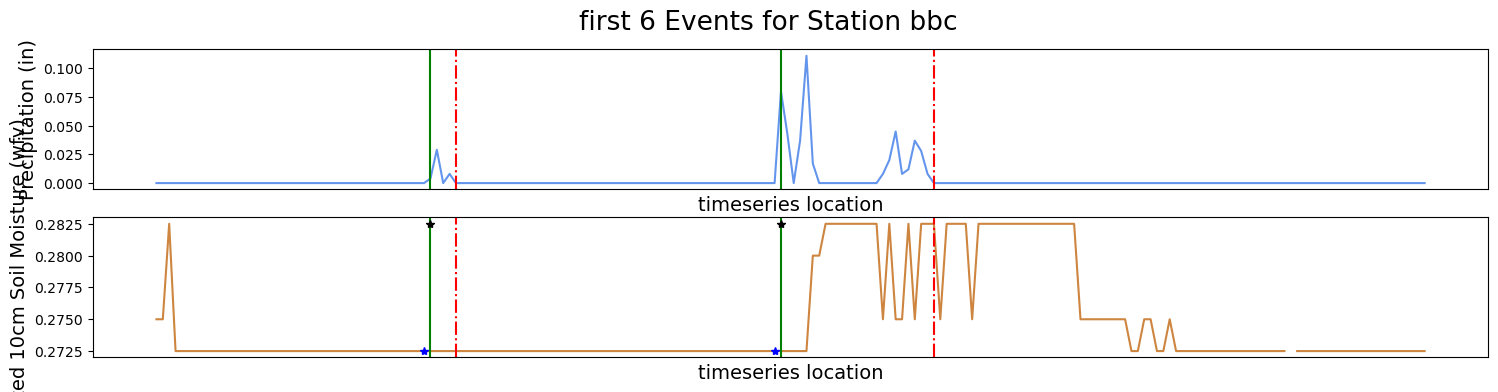

bbc
duration after events num loop 0       4.0
1      24.0
2       9.0
3       1.0
4      45.0
       ... 
728    23.0
729    31.0
730    30.0
731    40.0
732     1.0
Length: 733, dtype: float64
brw
event_end len = 652
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 40
station brw
current event start index 88871
current event end index 88873
next event start index 88988
Soil Moisture Change in 100cm is negative!
calc value = -0.0007999999999999674
n 40
station brw
current event start index 88871
current event end index 88873
next event start index 88988
Soil Moisture Change in 100cm is negative!
calc value = -0.0007000000000000339
n 123
station brw
current event start index 98224
current event end index 98226
next event start index 98595
Soil Moisture Change in 100cm is negative!
calc value = -0.00020000000000003348
n 147
station brw
current event start index 101387
current event end index 101392
next event start index 101443
Soil Moisture Change in 10cm

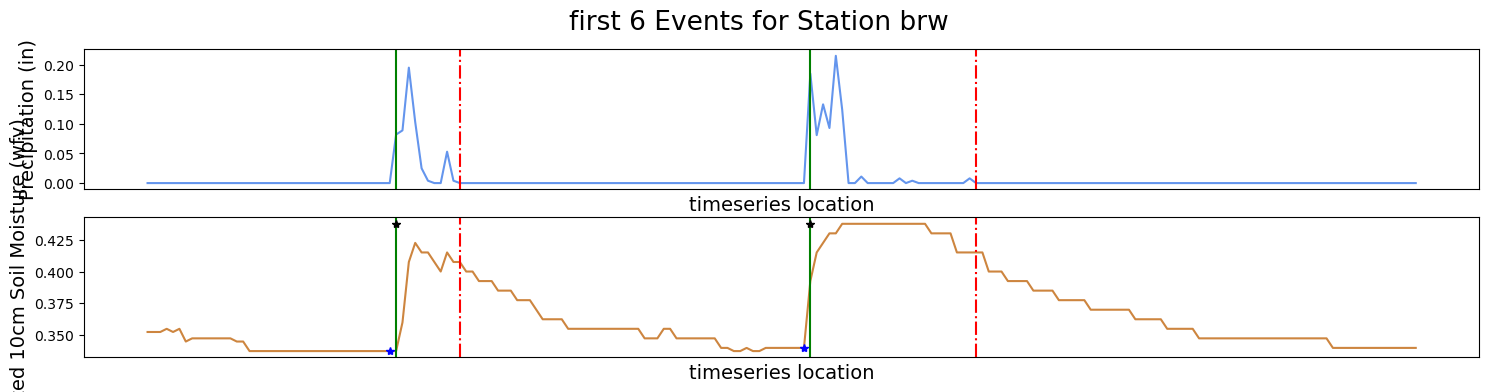

brw
duration after events num loop 0      10.0
1      26.0
2      18.0
3      23.0
4      43.0
       ... 
645    34.0
646     5.0
647    30.0
648    25.0
649     1.0
Length: 650, dtype: float64
bvl
event_end len = 681
Soil Moisture Change in 100cm is negative!
calc value = -0.00019999999999997797
n 16
station bvl
current event start index 163273
current event end index 163308
next event start index 163403
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 35
station bvl
current event start index 165014
current event end index 165020
next event start index 165160
Soil Moisture Change in 100cm is negative!
calc value = -0.0020000000000000018
n 88
station bvl
current event start index 171147
current event end index 171150
next event start index 171415
Soil Moisture Change in 10cm is negative!
calc value =  -0.0010000000000000009
n 135
station bvl
current event start index 177179
current event end index 177181
next event start index 177221
Soil Moisture Chang

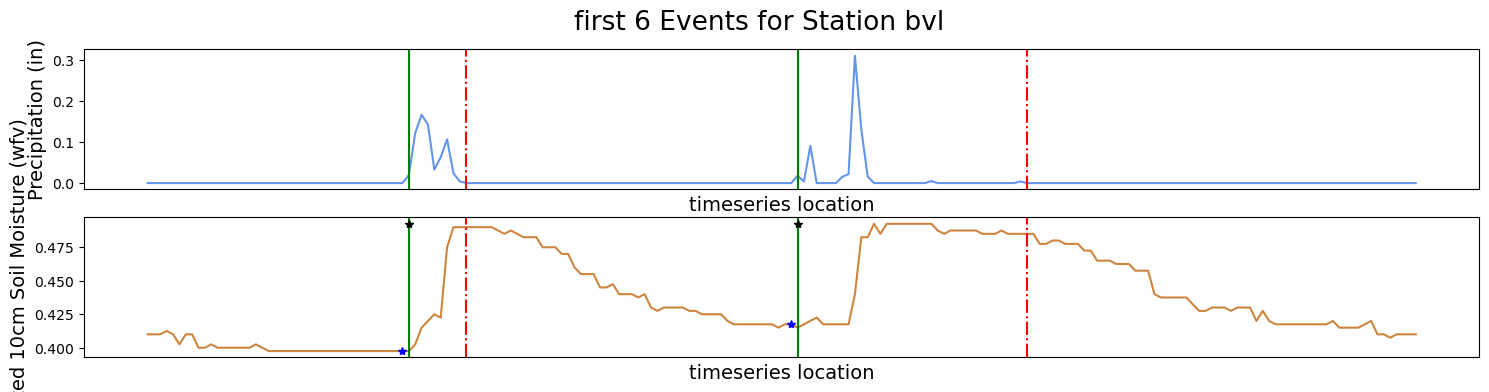

bvl
duration after events num loop 0       9.0
1      36.0
2       9.0
3      28.0
4      64.0
       ... 
674    25.0
675     1.0
676    11.0
677     9.0
678     6.0
Length: 679, dtype: float64
cmi
event_end len = 694
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 67
station cmi
current event start index 246123
current event end index 246124
next event start index 246217
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 199
station cmi
current event start index 261377
current event end index 261396
next event start index 261433
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 200
station cmi
current event start index 261433
current event end index 261451
next event start index 261477
Soil Moisture Change in 100cm is negative!
calc value = -0.0006999999999999784
n 200
station cmi
current event start index 261433
current event end index 261451
next event start index 261477
Soil Moisture Chang

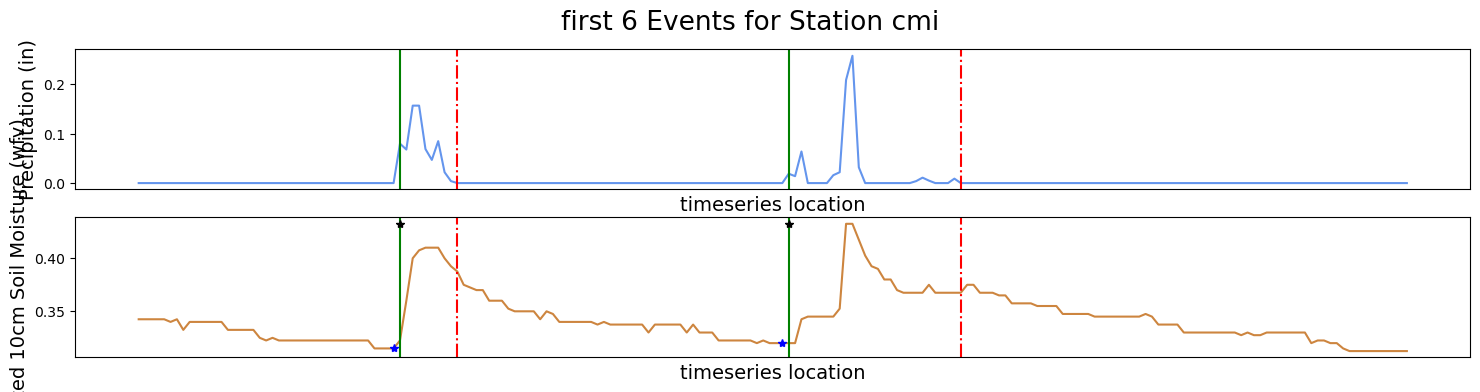

cmi
duration after events num loop 0       9.0
1      27.0
2       9.0
3      29.0
4      64.0
       ... 
687    26.0
688    13.0
689    10.0
690     1.0
691    27.0
Length: 692, dtype: float64
dek
event_end len = 762
Soil Moisture Change in 100cm is negative!
calc value = -0.0006000000000000449
n 16
station dek
current event start index 317383
current event end index 317384
next event start index 317410
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 19
station dek
current event start index 317531
current event end index 317532
next event start index 317571
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 19
station dek
current event start index 317531
current event end index 317532
next event start index 317571
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 136
station dek
current event start index 329724
current event end index 329725
next event start index 329827
Soil Moisture Change 

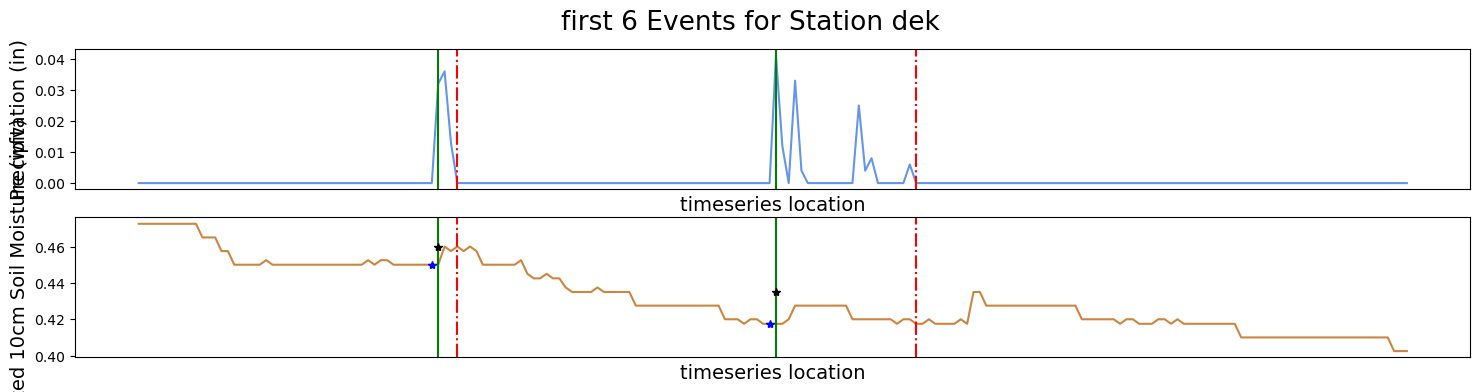

dek
duration after events num loop 0       3.0
1      22.0
2      12.0
3      62.0
4       3.0
       ... 
757    71.0
758     1.0
759    28.0
760    65.0
761     3.0
Length: 762, dtype: float64
dxs
event_end len = 641
Soil Moisture Change in 100cm is negative!
calc value = -0.0012999999999999678
n 30
station dxs
current event start index 395888
current event end index 395889
next event start index 396081
Soil Moisture Change in 10cm is negative!
calc value =  -0.0010000000000000009
n 117
station dxs
current event start index 408142
current event end index 408211
next event start index 408235
Soil Moisture Change in 100cm is negative!
calc value = -0.0010000000000000009
n 124
station dxs
current event start index 408739
current event end index 408740
next event start index 408773
Soil Moisture Change in 10cm is negative!
calc value =  -0.012400000000000022
n 129
station dxs
current event start index 409330
current event end index 409340
next event start index 409483
Soil Moisture Chang

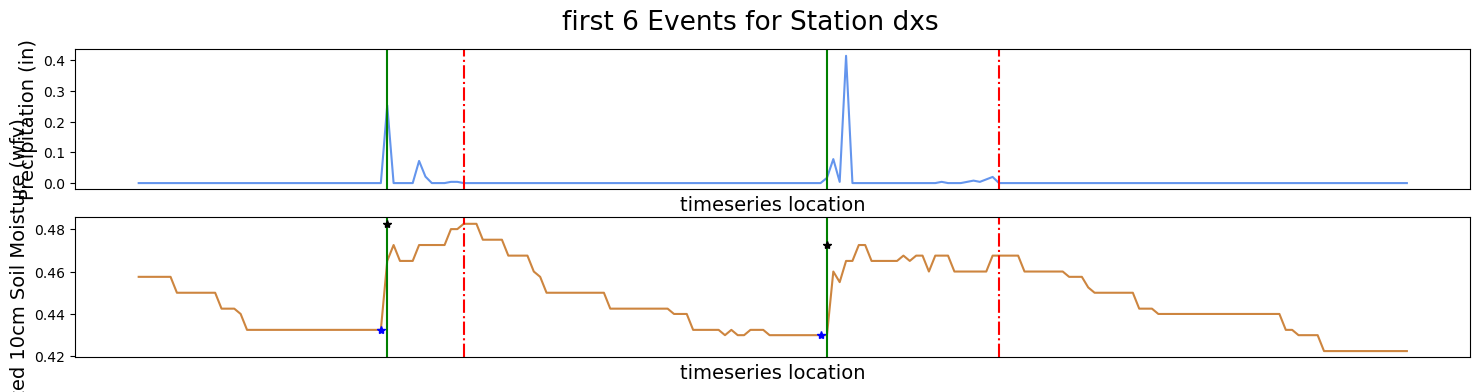

dxs
duration after events num loop 0      12.0
1      27.0
2      27.0
3      28.0
4      52.0
       ... 
634    28.0
635    21.0
636    20.0
637     5.0
638     2.0
Length: 639, dtype: float64
fai
event_end len = 642
Soil Moisture Change in 10cm is negative!
calc value =  -0.0050000000000000044
n 23
station fai
current event start index 472066
current event end index 472067
next event start index 472128
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 45
station fai
current event start index 475208
current event end index 475215
next event start index 475358
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 61
station fai
current event start index 476693
current event end index 476694
next event start index 476732
Soil Moisture Change in 100cm is negative!
calc value = -0.0012999999999999678
n 98
station fai
current event start index 482062
current event end index 482069
next event start index 482215
Soil Moisture Change 

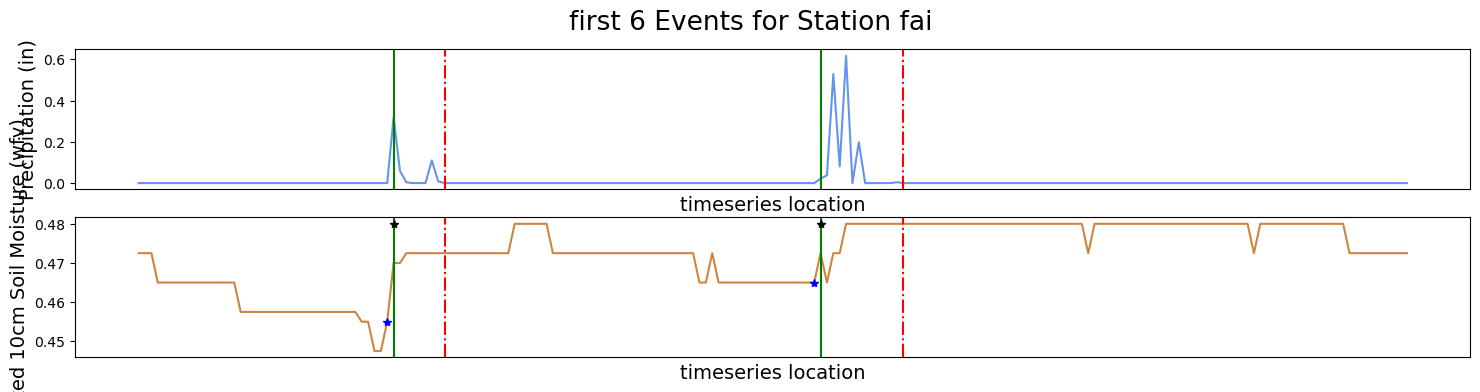

fai
duration after events num loop 0       8.0
1      13.0
2      26.0
3      30.0
4      24.0
       ... 
635    17.0
636    50.0
637     8.0
638     9.0
639     5.0
Length: 640, dtype: float64
fre
event_end len = 692
Soil Moisture Change in 10cm is negative!
calc value =  -0.004999999999999949
n 18
station fre
current event start index 548814
current event end index 548815
next event start index 548969
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 32
station fre
current event start index 550306
current event end index 550307
next event start index 550852
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 45
station fre
current event start index 551887
current event end index 551893
next event start index 551935
Soil Moisture Change in 100cm is negative!
calc value = -0.0007000000000000339
n 61
station fre
current event start index 553549
current event end index 553550
next event start index 553580
Soil Moisture Change i

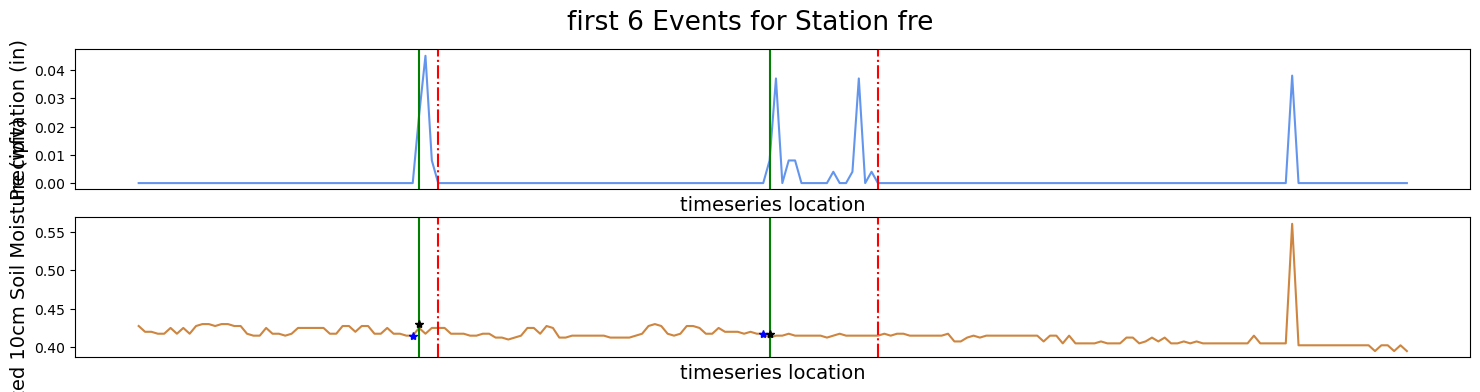

fre
duration after events num loop 0       3.0
1      17.0
2       1.0
3       8.0
4      37.0
       ... 
687    68.0
688     6.0
689    68.0
690    27.0
691    37.0
Length: 692, dtype: float64
frm
event_end len = 664
Soil Moisture Change in 10cm is negative!
calc value =  -0.012499999999999956
n 6
station frm
current event start index 624277
current event end index 624278
next event start index 624377
Soil Moisture Change in 10cm is negative!
calc value =  -0.06749999999999998
n 9
station frm
current event start index 624572
current event end index 624595
next event start index 624628
Soil Moisture Change in 100cm is negative!
calc value = -0.016699999999999993
n 9
station frm
current event start index 624572
current event end index 624595
next event start index 624628
Soil Moisture Change in 100cm is negative!
calc value = -0.0032999999999999696
n 25
station frm
current event start index 626158
current event end index 626159
next event start index 626188
Soil Moisture Change in 100c

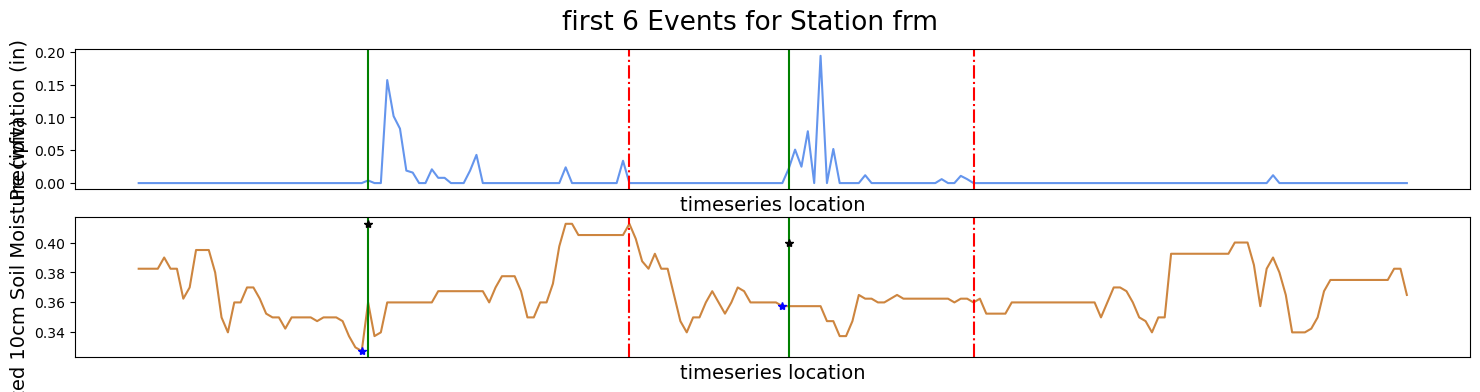

frm
duration after events num loop 0       41.0
1       29.0
2        1.0
3       24.0
4      123.0
       ...  
657      2.0
658      6.0
659      2.0
660     38.0
661      1.0
Length: 662, dtype: float64
icc
event_end len = 705
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 160
station icc
current event start index 728032
current event end index 728033
next event start index 728123
Soil Moisture Change in 100cm is negative!
calc value = -0.0005000000000000004
n 170
station icc
current event start index 728798
current event end index 728800
next event start index 728847
Soil Moisture Change in 10cm is negative!
calc value =  -0.0007999999999999952
n 174
station icc
current event start index 729274
current event end index 729424
next event start index 729489
Soil Moisture Change in 10cm is negative!
calc value =  -0.0007000000000000062
n 177
station icc
current event start index 729944
current event end index 729951
next event start index 730026
Soil M

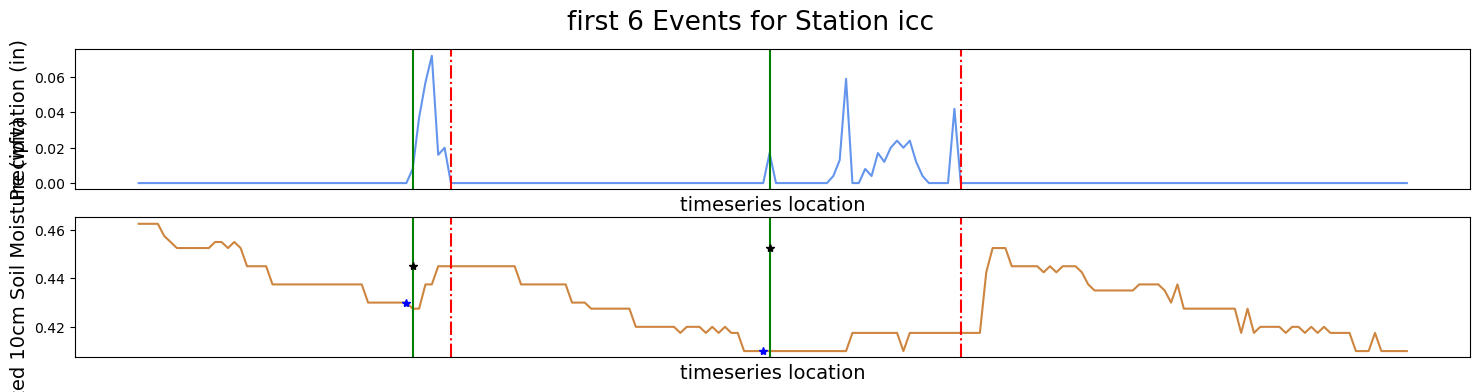

icc
duration after events num loop 0       6.0
1      30.0
2      10.0
3      21.0
4      56.0
       ... 
698    37.0
699     3.0
700     6.0
701     2.0
702    33.0
Length: 703, dtype: float64
llc
event_end len = 651
Soil Moisture Change in 100cm is negative!
calc value = -0.0007000000000000339
n 17
station llc
current event start index 789859
current event end index 789861
next event start index 789977
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 21
station llc
current event start index 790216
current event end index 790217
next event start index 790250
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 38
station llc
current event start index 792594
current event end index 792595
next event start index 792623
Soil Moisture Change in 10cm is negative!
calc value =  -0.0022999999999999965
n 132
station llc
current event start index 803705
current event end index 803713
next event start index 803763
Soil Moisture Change

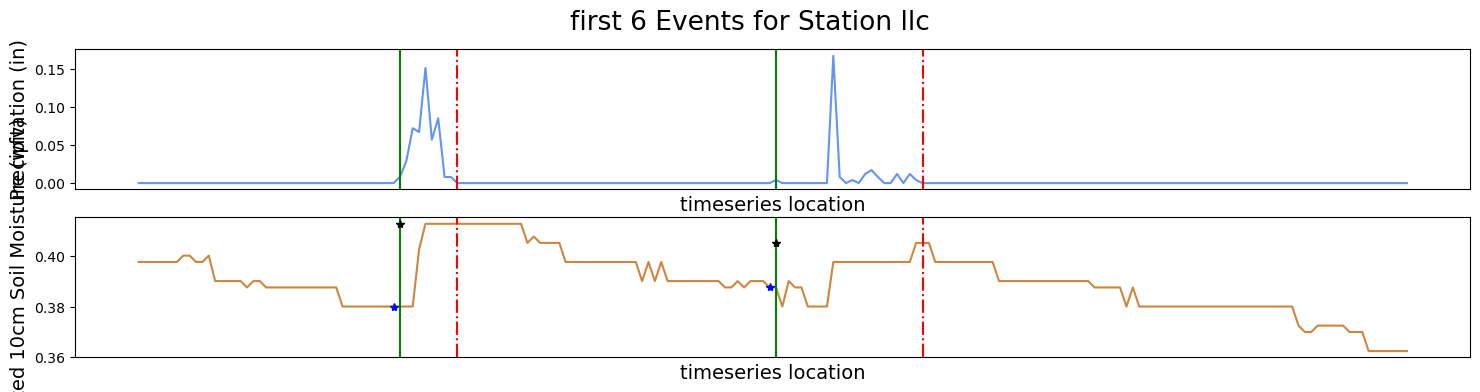

llc
duration after events num loop 0       9.0
1      23.0
2      12.0
3      18.0
4      37.0
       ... 
644     2.0
645    10.0
646    37.0
647     6.0
648    11.0
Length: 649, dtype: float64
mon
event_end len = 716
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 70
station mon
current event start index 872312
current event end index 872318
next event start index 872374
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 70
station mon
current event start index 872312
current event end index 872318
next event start index 872374
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 94
station mon
current event start index 875182
current event end index 875183
next event start index 875423
Soil Moisture Change in 100cm is negative!
calc value = -0.0007000000000000062
n 94
station mon
current event start index 875182
current event end index 875183
next event start index 875423
Soil Moisture Change i

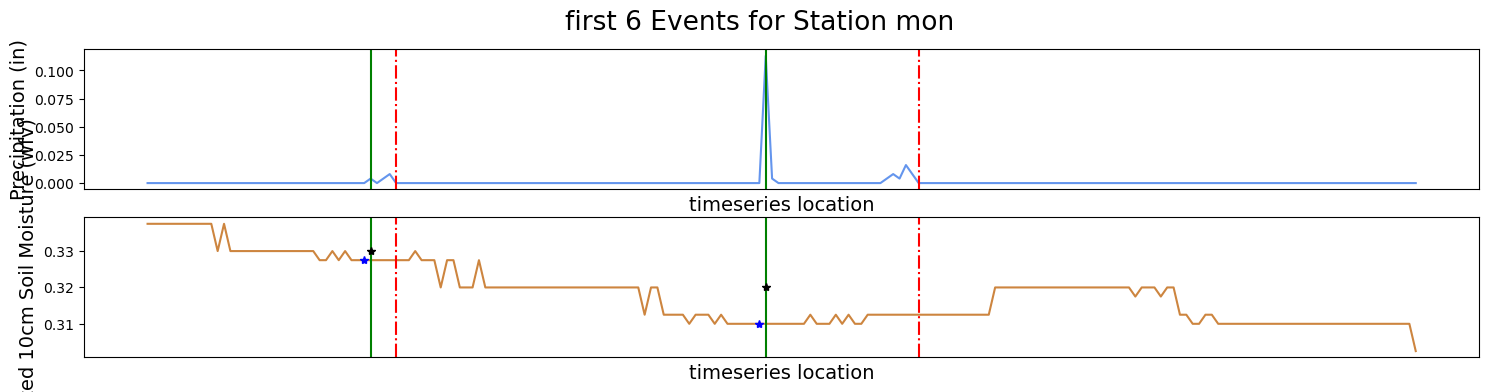

mon
duration after events num loop 0       4.0
1      24.0
2      23.0
3       1.0
4      50.0
       ... 
709     3.0
710     1.0
711     2.0
712    37.0
713    16.0
Length: 714, dtype: float64
oln
event_end len = 667
Soil Moisture Change in 100cm is negative!
calc value = -0.0006999999999999784
n 128
station oln
current event start index 959704
current event end index 959720
next event start index 959778
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 136
station oln
current event start index 961278
current event end index 961280
next event start index 961350
Soil Moisture Change in 10cm is negative!
calc value =  -0.0007000000000000062
n 149
station oln
current event start index 962596
current event end index 962601
next event start index 962793
Soil Moisture Change in 100cm is negative!
calc value = -0.0009000000000000119
n 149
station oln
current event start index 962596
current event end index 962601
next event start index 962793
Soil Moisture Chan

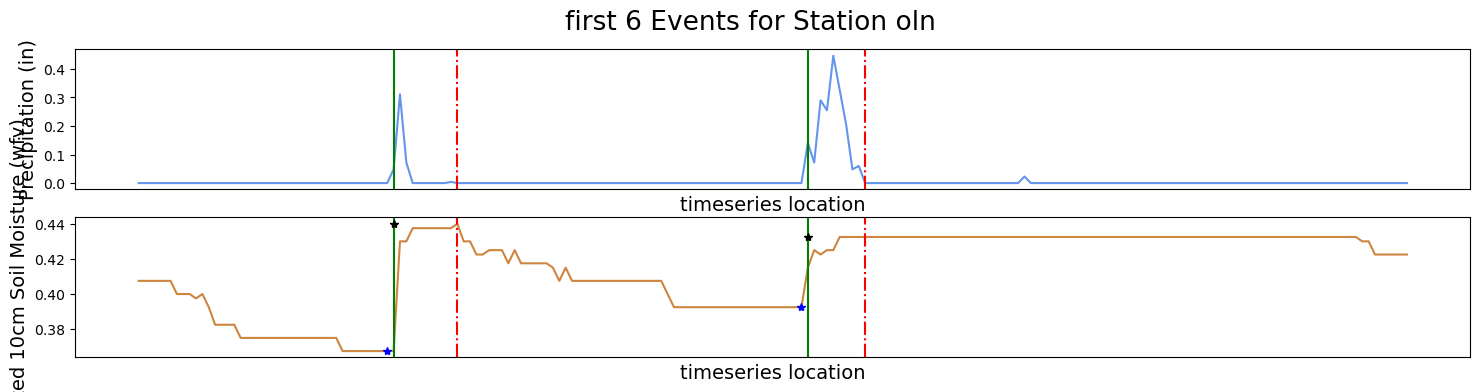

oln
duration after events num loop 0      10.0
1       9.0
2       1.0
3      25.0
4      26.0
       ... 
660    17.0
661    13.0
662    18.0
663    31.0
664    25.0
Length: 665, dtype: float64
orr
event_end len = 676
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 163
station orr
current event start index 1047920
current event end index 1047945
next event start index 1048078
Soil Moisture Change in 10cm is negative!
calc value =  -0.0015000000000000013
n 164
station orr
current event start index 1048078
current event end index 1048083
next event start index 1048265
Soil Moisture Change in 100cm is negative!
calc value = -9.999999999998899e-05
n 164
station orr
current event start index 1048078
current event end index 1048083
next event start index 1048265
Soil Moisture Change in 100cm is negative!
calc value = -0.0005000000000000004
n 167
station orr
current event start index 1048451
current event end index 1048470
next event start index 1048521
Soil 

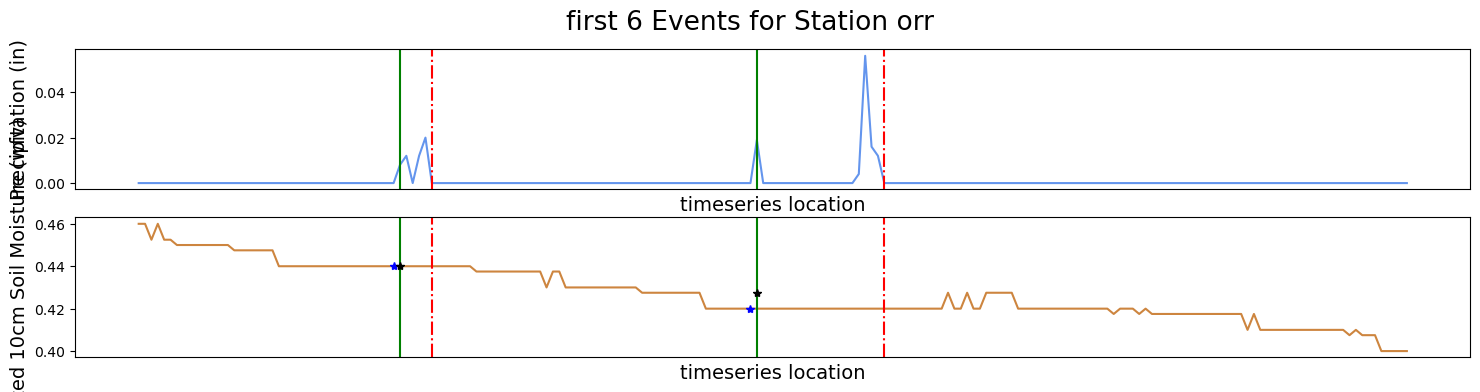

orr
duration after events num loop 0       5.0
1      20.0
2      14.0
3      36.0
4      35.0
       ... 
669     1.0
670    29.0
671    82.0
672    28.0
673     1.0
Length: 674, dtype: float64
rnd
event_end len = 690
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 17
station rnd
current event start index 1110577
current event end index 1110579
next event start index 1110603
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 23
station rnd
current event start index 1111345
current event end index 1111355
next event start index 1111430
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 27
station rnd
current event start index 1111650
current event end index 1111651
next event start index 1111679
Soil Moisture Change in 100cm is negative!
calc value = -0.0015999999999999903
n 27
station rnd
current event start index 1111650
current event end index 1111651
next event start index 1111679
Soil Moistur

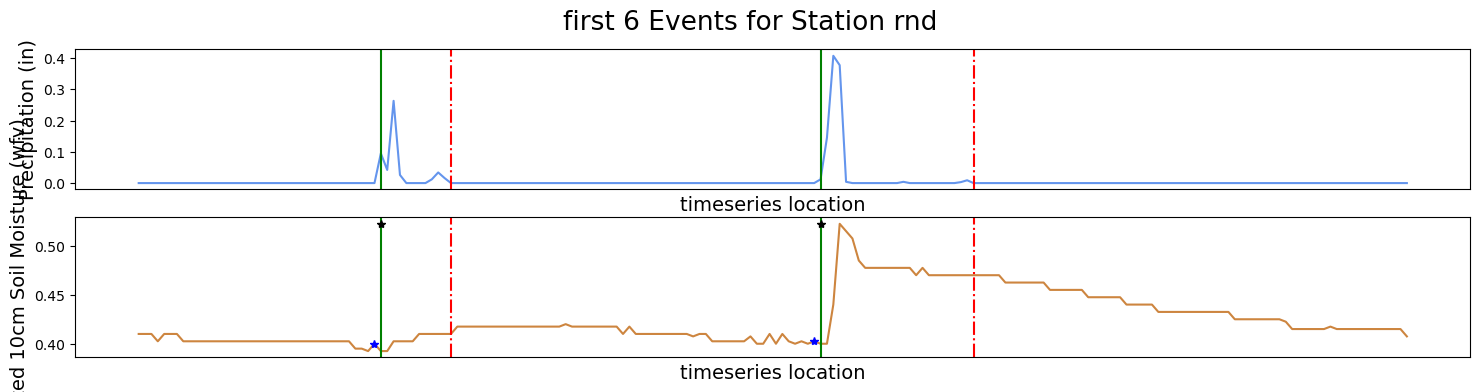

rnd
duration after events num loop 0      11.0
1      24.0
2      26.0
3      27.0
4      37.0
       ... 
683    35.0
684    25.0
685    48.0
686     1.0
687     5.0
Length: 688, dtype: float64
sfm
event_end len = 372
Soil Moisture Change in 10cm is negative!
calc value =  -0.0002999999999999999
n 142
station sfm
current event start index 1201451
current event end index 1201453
next event start index 1201502
Soil Moisture Change in 10cm is negative!
calc value =  -0.0022
n 161
station sfm
current event start index 1203154
current event end index 1203155
next event start index 1203182
Soil Moisture Change in 100cm is negative!
calc value = -0.0001999999999999988
n 197
station sfm
current event start index 1207215
current event end index 1207216
next event start index 1207249
Soil Moisture Change in 100cm is negative!
calc value = -0.0003999999999999976
n 200
station sfm
current event start index 1207354
current event end index 1207386
next event start index 1207432
Soil Moisture Change

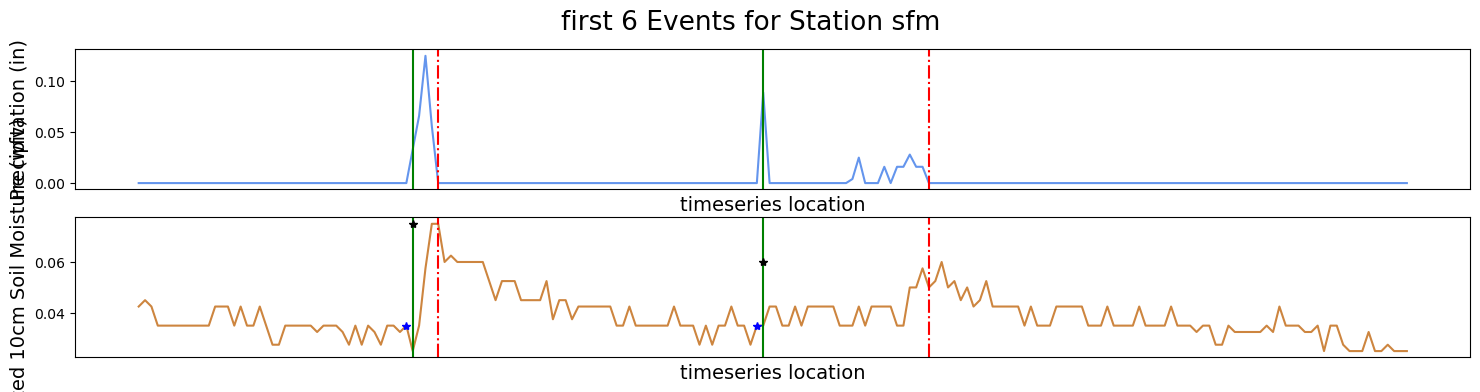

sfm
duration after events num loop 0       4.0
1      26.0
2      12.0
3      38.0
4      28.0
       ... 
365    45.0
366    26.0
367    16.0
368     2.0
369    11.0
Length: 370, dtype: float64
siu
event_end len = 667
Soil Moisture Change in 10cm is negative!
calc value =  -0.009999999999999953
n 20
station siu
current event start index 1228435
current event end index 1228436
next event start index 1228485
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 75
station siu
current event start index 1234360
current event end index 1234361
next event start index 1234526
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 75
station siu
current event start index 1234360
current event end index 1234361
next event start index 1234526
Soil Moisture Change in 100cm is negative!
calc value = -0.00020000000000003348
n 138
station siu
current event start index 1242727
current event end index 1242772
next event start index 1242797
Soil Mois

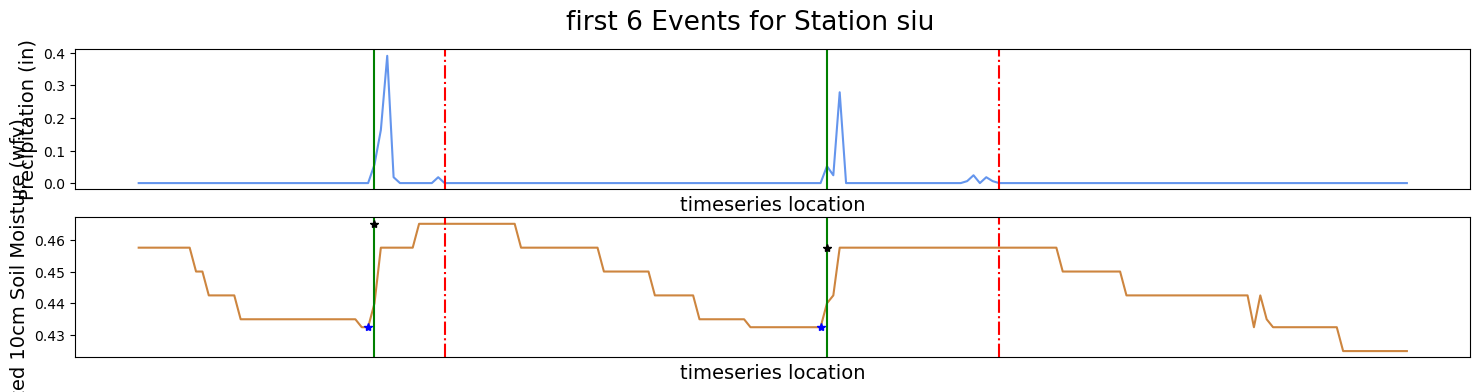

siu
duration after events num loop 0      11.0
1      27.0
2      27.0
3      31.0
4      32.0
       ... 
662    31.0
663    21.0
664    47.0
665     4.0
666    44.0
Length: 667, dtype: float64
sni
event_end len = 320
Soil Moisture Change in 10cm is negative!
calc value =  -0.0010000000000000009
n 13
station sni
current event start index 1304987
current event end index 1304989
next event start index 1305341
Soil Moisture Change in 100cm is negative!
calc value = -0.00010000000000000286
n 13
station sni
current event start index 1304987
current event end index 1304989
next event start index 1305341
Soil Moisture Change in 100cm is negative!
calc value = -0.0003999999999999976
n 16
station sni
current event start index 1305627
current event end index 1305628
next event start index 1305687
Soil Moisture Change in 10cm is negative!
calc value =  -0.0006999999999999923
n 38
station sni
current event start index 1308206
current event end index 1308208
next event start index 1308263
Soil Moi

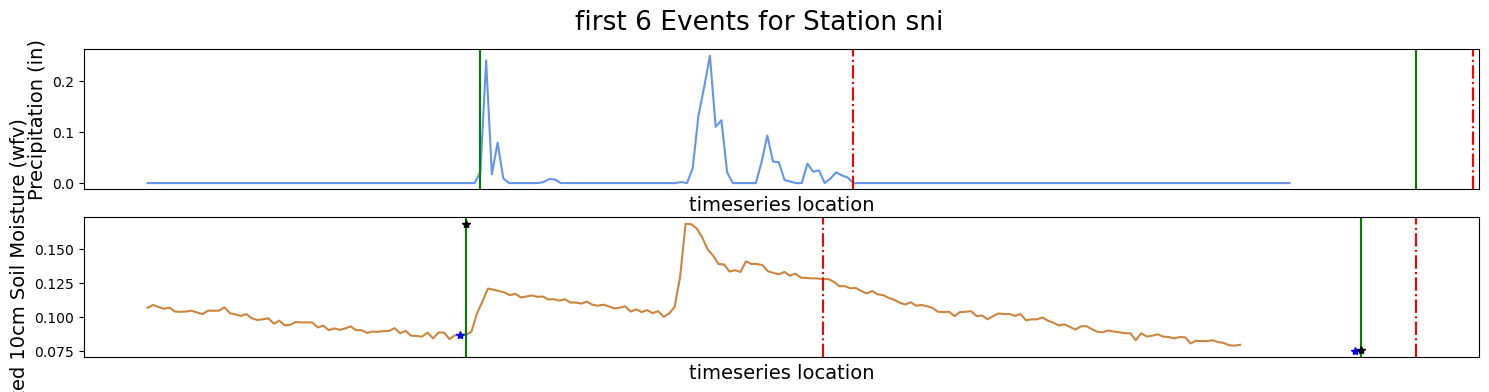

sni
duration after events num loop 0      65.0
1      10.0
2       8.0
3       6.0
4       2.0
       ... 
313     7.0
314     1.0
315     3.0
316     1.0
317    38.0
Length: 318, dtype: float64
stc
event_end len = 765
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 17
station stc
current event start index 1341217
current event end index 1341218
next event start index 1341252
Soil Moisture Change in 100cm is negative!
calc value = -0.0015000000000000013
n 43
station stc
current event start index 1343816
current event end index 1343818
next event start index 1343906
Soil Moisture Change in 100cm is negative!
calc value = -0.0013000000000000234
n 159
station stc
current event start index 1362300
current event end index 1362320
next event start index 1362386
Soil Moisture Change in 10cm is negative!
calc value =  -0.002599999999999991
n 164
station stc
current event start index 1362784
current event end index 1362810
next event start index 1362948
Soil Moi

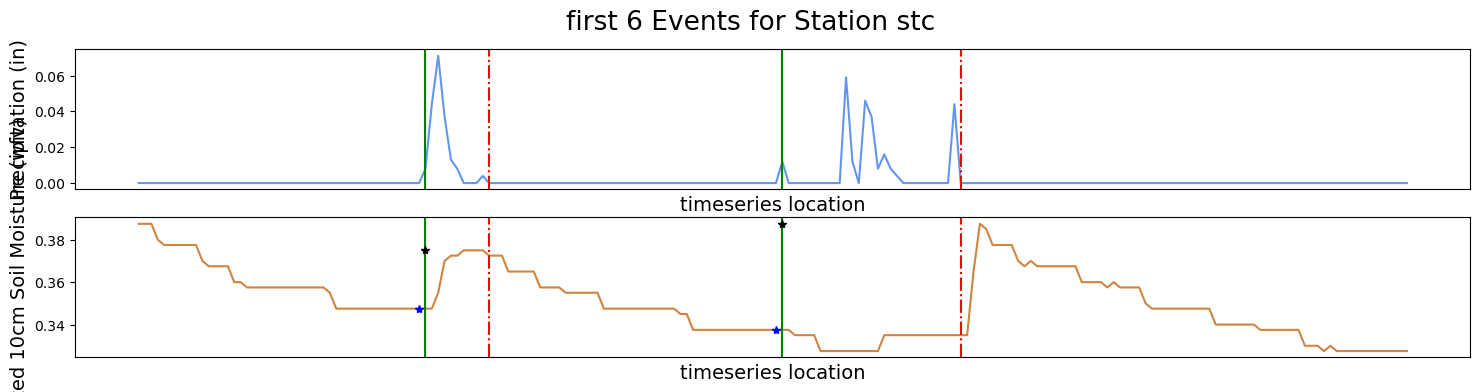

stc
duration after events num loop 0      10.0
1      28.0
2       1.0
3      23.0
4      61.0
       ... 
760     6.0
761    71.0
762    27.0
763    66.0
764     2.0
Length: 765, dtype: float64
ste
event_end len = 737
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 38
station ste
current event start index 1428530
current event end index 1428531
next event start index 1428560
Soil Moisture Change in 10cm is negative!
calc value =  -0.0025000000000000022
n 89
station ste
current event start index 1433647
current event end index 1433649
next event start index 1433798
Soil Moisture Change in 100cm is negative!
calc value = -0.0008000000000000229
n 89
station ste
current event start index 1433647
current event end index 1433649
next event start index 1433798
Soil Moisture Change in 10cm is negative!
calc value =  -0.007500000000000007
n 101
station ste
current event start index 1435067
current event end index 1435068
next event start index 1435092
Soil Moist

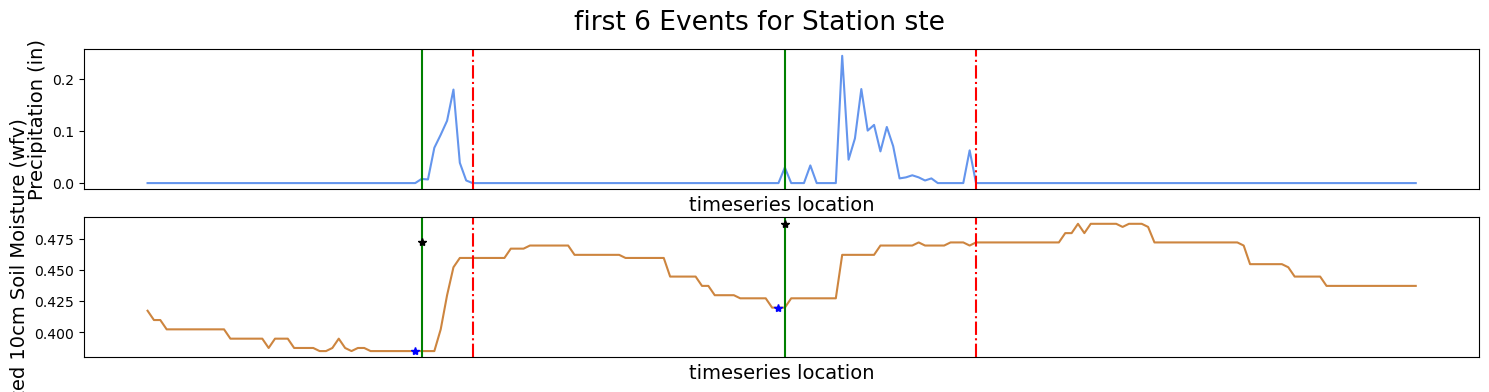

ste
duration after events num loop 0       8.0
1      30.0
2       8.0
3      20.0
4      68.0
       ... 
730     3.0
731    20.0
732    16.0
733    30.0
734    26.0
Length: 735, dtype: float64
13097
13097


In [24]:
#Event_vars_df = Rain_events_data(WeightedSM_data_stormID) 
Apr_2_oct_Event_vars_df = Rain_events_data(Apr_2_Oct_WeightedSM_data_stormID)

In [25]:
Apr_2_oct_Event_vars_df.head()

,Station,Event_Duration,Avg_Precipitation_rate_in,Peak_Precipitation_rate_in,Median_Precipitation_rate_in,Total_Precipitation_in,Prior_sm_10,Peak_sm_10,Prior_sm_100,Peak_sm_100
0,bbc,4.0,0.010250,0.029,0.006,0.041,0.2725,0.2825,0.1598,0.1618
1,bbc,24.0,0.018917,0.111,0.008,0.454,0.2725,0.2825,0.1558,0.1608
2,bbc,9.0,0.084556,0.258,0.054,0.761,0.2650,0.2900,0.1530,0.1642
3,bbc,1.0,0.005000,0.005,0.005,0.005,0.2725,0.2725,0.1608,0.1618
4,bbc,45.0,0.034756,0.246,0.001,1.564,0.2725,0.3000,0.1572,0.1732


### Calculate the difference in soil moisture values the delta(sm) we are interested in how precipitaiton changes the sm recharge

In [28]:
#this function assumes that the data is in the same structure I created earlier where the first sm 
#data column is 'Prior_sm_##' and there after alternates with its corresponding 'Peak_sm_##' to the 
#last column
def delta_sm(data):
    first_prior_sm_col = data.columns.str.contains('Prior_sm_').argmax() #.argmax returns the column index
    sm_cols = data.columns[first_prior_sm_col:] #pulls out all columns from first sm col to last
    ptot_col = data.columns[data.columns.str.contains('Total').argmax()]
    for col in sm_cols:
        if col.startswith('Prior_sm_'):
            depth = col.split('_')[-1]
            peak_col = f'Peak_sm_{depth}'
            delta_col = f'Delta_sm_{depth}'

            #check if the corresponding peak sm column exists to calculate the delta

            if peak_col in data.columns:
                data[delta_col] = data[peak_col] - data[col]
                data[delta_col+'_perPtot'] = data[delta_col]/data[ptot_col]

                data.loc[(data[delta_col + '_perPtot'] > 1) & (data[delta_col + '_perPtot'] <= 1.25),( delta_col + '_perPtot')] = 1.0
                indices_to_drop = data.loc[data[delta_col + '_perPtot'] > 1.25].index
                data.drop(index = indices_to_drop, inplace = True)
    
    return  data

### delete the events with delta sm < -0.01

 then change the others which are negative but -0.00## since this is beyond sensor precision

In [29]:
Apr_2_oct_Event_vars_delta_df = delta_sm(data = Apr_2_oct_Event_vars_df)
Apr_2_oct_Event_vars_delta_df.loc[Apr_2_oct_Event_vars_delta_df['Delta_sm_10'] < -0.01, ('Delta_sm_10', 'Delta_sm_10_perPtot')] = 0
Apr_2_oct_Event_vars_delta_df.loc[Apr_2_oct_Event_vars_delta_df['Delta_sm_100'] < -0.01, ('Delta_sm_100', 'Delta_sm_100_perPtot')] = 0
#delete the events with < -0.01
Apr_2_oct_Event_vars_delta_df.drop(Apr_2_oct_Event_vars_delta_df[Apr_2_oct_Event_vars_delta_df['Delta_sm_100'] < 0.0].index, inplace = True)

Apr_2_oct_Event_vars_delta_df.drop(Apr_2_oct_Event_vars_delta_df[Apr_2_oct_Event_vars_delta_df['Delta_sm_10'] < 0.0].index, inplace = True)

In [30]:
Apr_2_oct_Event_vars_delta_df.head()

,Station,Event_Duration,Avg_Precipitation_rate_in,Peak_Precipitation_rate_in,Median_Precipitation_rate_in,Total_Precipitation_in,Prior_sm_10,Peak_sm_10,Prior_sm_100,Peak_sm_100,Delta_sm_10,Delta_sm_10_perPtot,Delta_sm_100,Delta_sm_100_perPtot
0,bbc,4.0,0.010250,0.029,0.006,0.041,0.2725,0.2825,0.1598,0.1618,0.0100,0.243902,0.0020,0.048780
1,bbc,24.0,0.018917,0.111,0.008,0.454,0.2725,0.2825,0.1558,0.1608,0.0100,0.022026,0.0050,0.011013
2,bbc,9.0,0.084556,0.258,0.054,0.761,0.2650,0.2900,0.1530,0.1642,0.0250,0.032852,0.0112,0.014717
3,bbc,1.0,0.005000,0.005,0.005,0.005,0.2725,0.2725,0.1608,0.1618,0.0000,0.000000,0.0010,0.200000
4,bbc,45.0,0.034756,0.246,0.001,1.564,0.2725,0.3000,0.1572,0.1732,0.0275,0.017583,0.0160,0.010230


In [31]:
def min_max_normalization(data_multi_df):
    stations = data_multi_df.Station.unique()
    normalized_data_multi_df =[]
    min_max_mean_med_cols = []
    col_to_normalize_list = data_multi_df.columns[
        data_multi_df.columns.str.contains('Precipitation|sm')].tolist()
    print(col_to_normalize_list)
    for s in stations:
        station_df = data_multi_df.loc[data_multi_df['Station'] == s].copy()
        print(s)

        sm_100_cols = station_df.columns[(station_df.columns.str.contains('sm_100')) &
                                         (station_df.columns.str.contains('Peak|Prior'))]
        sm_100_min = station_df[sm_100_cols].to_numpy().ravel().min()
        sm_100_max = station_df[sm_100_cols].to_numpy().ravel().max()

        sm_10_cols = station_df.columns[
                                (station_df.columns.str.contains('Peak_sm|Prior_sm')) &
                                ~(station_df.columns.str.contains('sm_100'))]
        sm_10_min = station_df[sm_10_cols].to_numpy().ravel().min()
        sm_10_max = station_df[sm_10_cols].to_numpy().ravel().max()


        for col in col_to_normalize_list:
            if 'Precipitation' in col or 'Delta' in col:
                station_df_col_min = station_df[col].min()
                station_df_col_max = station_df[col].max()
            elif 'sm_100' in col:
                station_df_col_min = sm_100_min
                station_df_col_max = sm_100_max   
            else:
                station_df_col_min = sm_10_min
                station_df_col_max = sm_10_max
                
            station_df_col_mean = station_df[col].mean()
            station_df_col_median = station_df[col].median()
            
            station_df.loc[:,col] = ((station_df[col] - station_df_col_min) / 
                               (station_df_col_max - station_df_col_min))
            
            min_max_mean_med_cols.append({
                                    'Station': s,
                                    'Variable': col, 
                                    'Min': station_df_col_min, 
                                    'Max': station_df_col_max, 
                                    'Mean': station_df_col_mean, 
                                    'Median': station_df_col_median})
        

        normalized_data_multi_df.append(station_df)
    normalized_data_multi_df = pd.concat(normalized_data_multi_df, axis = 0).reset_index(drop = True)
    min_max_mean_med_df = pd.DataFrame(min_max_mean_med_cols)
        
    return normalized_data_multi_df, min_max_mean_med_df


In [32]:
Apr_2_Oct_Station_events_df_normalized, min_max_data_df = min_max_normalization(Apr_2_oct_Event_vars_delta_df)

['Avg_Precipitation_rate_in', 'Peak_Precipitation_rate_in', 'Median_Precipitation_rate_in', 'Total_Precipitation_in', 'Prior_sm_10', 'Peak_sm_10', 'Prior_sm_100', 'Peak_sm_100', 'Delta_sm_10', 'Delta_sm_10_perPtot', 'Delta_sm_100', 'Delta_sm_100_perPtot']
bbc
brw
bvl
cmi
dek
dxs
fai
fre
frm
icc
llc
mon
oln
orr
rnd
sfm
siu
sni
stc
ste


In [36]:
Apr_2_Oct_Station_events_df_normalized.head()

,Station,Event_Duration,Avg_Precipitation_rate_in,Peak_Precipitation_rate_in,Median_Precipitation_rate_in,Total_Precipitation_in,Prior_sm_10,Peak_sm_10,Prior_sm_100,Peak_sm_100,Delta_sm_10,Delta_sm_10_perPtot,Delta_sm_100,Delta_sm_100_perPtot
0,bbc,4.0,0.008969,0.011180,0.005376,0.007217,0.854815,0.891852,0.707143,0.720130,0.052994,0.243902,0.030030,0.048780
1,bbc,24.0,0.016737,0.045135,0.007168,0.083642,0.854815,0.891852,0.681169,0.713636,0.052994,0.022026,0.075075,0.011013
2,bbc,9.0,0.075566,0.106004,0.048387,0.140452,0.827037,0.919630,0.662987,0.735714,0.132485,0.032852,0.168168,0.014717
3,bbc,1.0,0.004264,0.001242,0.004480,0.000555,0.854815,0.854815,0.713636,0.720130,0.000000,0.000000,0.015015,0.200000
4,bbc,45.0,0.030932,0.101035,0.000896,0.289045,0.854815,0.956667,0.690260,0.794156,0.145734,0.017583,0.240240,0.010230


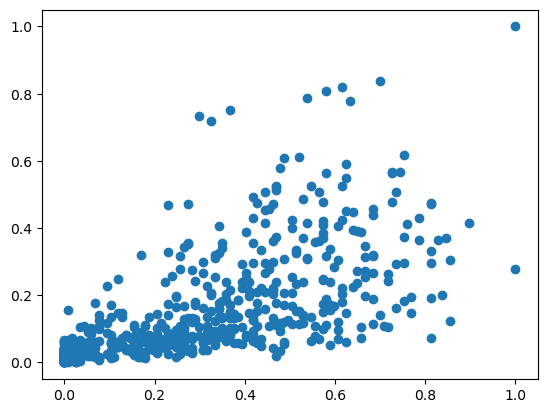

In [35]:
cmi_data = Apr_2_Oct_Station_events_df_normalized.loc[Apr_2_Oct_Station_events_df_normalized['Station'] == 'cmi']
plt.scatter(cmi_data['Delta_sm_10'], cmi_data['Peak_Precipitation_rate_in'])

### Normalize data (rescale to [0,1]) with min-max scaling

## x-xmin/(xmax - xmin)
this will not change the data shape only it's range and thus it maintains it underlying behaviors and relationships in paired data


this will also help with the distance issue in the curse of dimensionality for the joint distribution

In [ ]:
min_max_data_df.loc[min_max_data_df['Station']=='bbc']
#the max values aren't rounded theyre just displaying that way for some weird pandas reason

In [ ]:
bbc_data = Apr_2_Oct_Station_events_df_normalized.loc[Apr_2_Oct_Station_events_df_normalized['Station'] == 'bbc']
plt.scatter(bbc_data.Prior_sm_10, bbc_data.Peak_Precipitation_rate_in)

In [ ]:
plt.scatter(bbc_data.Prior_sm_10, bbc_data.Delta_sm_10)

In [ ]:
plt.scatter(bbc_data.Delta_sm_100, bbc_data.Total_Precipitation_in)

In [37]:
#adjust data within function to be dictionary of multiple dfs
def Layer_dfs(data):
    data_columns = data.columns[1:]
    Stations = data.Station.unique()
    multi_dfs = {} #make dictionary of multiple dfs
    for d in Stations:
        print(f'Creating df for {d}')
        #initialize empty single df
        single_df = pd.DataFrame()
        for col in data_columns:
            single_df[col] = data.loc[data.Station == d, col]
        #store single df in dictionary of multiple dfs

        multi_dfs[d] = single_df
    return multi_dfs
#station_dfs = Layer_dfs(Event_vars_df)


In [38]:
Apr_2_Oct_station_dfs = Layer_dfs(Apr_2_Oct_Station_events_df_normalized)

Creating df for bbc
Creating df for brw
Creating df for bvl
Creating df for cmi
Creating df for dek
Creating df for dxs
Creating df for fai
Creating df for fre
Creating df for frm
Creating df for icc
Creating df for llc
Creating df for mon
Creating df for oln
Creating df for orr
Creating df for rnd
Creating df for sfm
Creating df for siu
Creating df for sni
Creating df for stc
Creating df for ste


In [39]:
#save data and kde df
import pickle

with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_priorpeaktogether2_delta_perPtot.pkl", "wb") as f:
    pickle.dump(Apr_2_Oct_station_dfs, f)